In [1]:
!pip install -q gradio

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

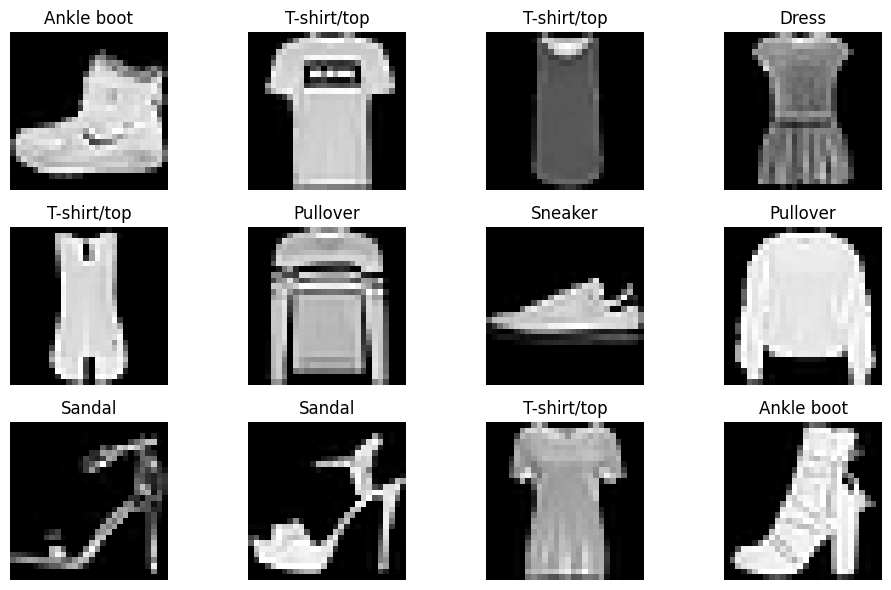

In [5]:
plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [7]:
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print(x_train.shape)

(60000, 28, 28, 1)


In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(10, activation="softmax")
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 54ms/step - accuracy: 0.7985 - loss: 0.5577 - val_accuracy: 0.8548 - val_loss: 0.3820
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.8660 - loss: 0.3679 - val_accuracy: 0.8795 - val_loss: 0.3266
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 56ms/step - accuracy: 0.8836 - loss: 0.3212 - val_accuracy: 0.8945 - val_loss: 0.2892
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.8949 - loss: 0.2893 - val_accuracy: 0.8965 - val_loss: 0.2797
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9019 - loss: 0.2661 - val_accuracy: 0.9017 - val_loss: 0.2705
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 57ms/step - accuracy: 0.9095 - loss: 0.2471 - val_accuracy: 0.9063 - val_loss: 0.2518
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - accuracy: 0.9154 - loss: 0.2308 - val_accuracy: 0.9110 - val_loss: 0.2414
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9204 - loss: 0.2136 - 

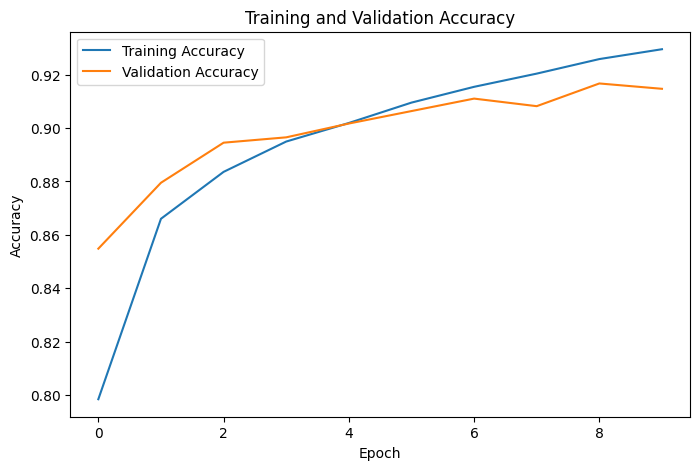

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.show()

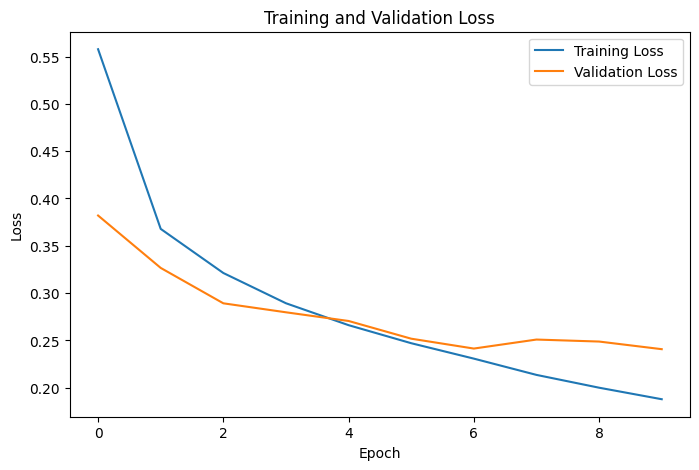

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9083 - loss: 0.2597
Test Loss: 0.25969594717025757
Test Accuracy: 0.90829998254776


In [15]:
predictions = model.predict(x_test)

y_pred = np.argmax(predictions, axis=1)

print(y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step
[9 2 1 1 6 1 4 6 5 7]


In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.84      0.87      0.85      1000
       Dress       0.91      0.92      0.92      1000
        Coat       0.89      0.83      0.86      1000
      Sandal       0.97      0.98      0.98      1000
       Shirt       0.72      0.76      0.74      1000
     Sneaker       0.96      0.96      0.96      1000
         Bag       0.97      0.98      0.98      1000
  Ankle boot       0.97      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



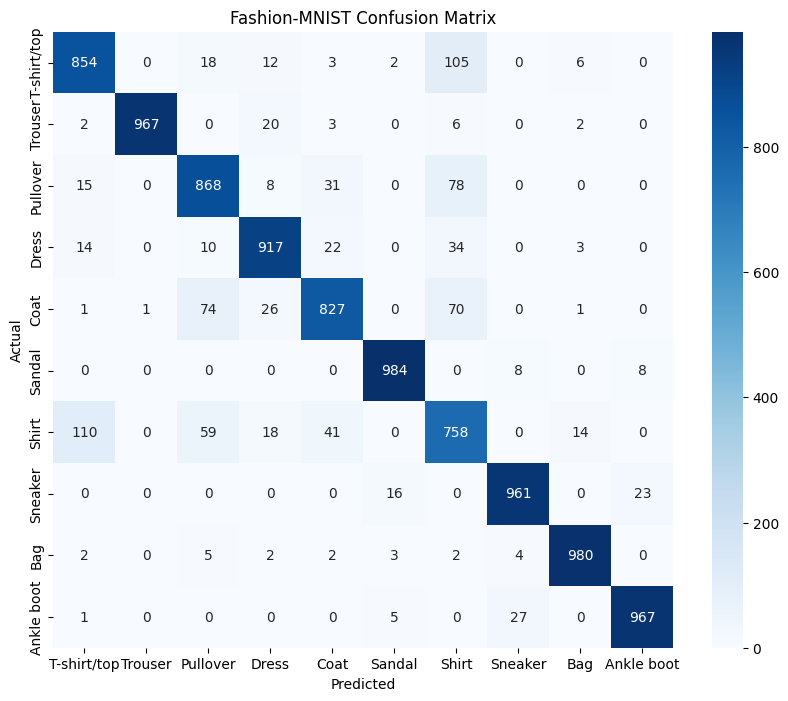

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fashion-MNIST Confusion Matrix")

plt.show()

In [18]:
index = 100

image = x_test[index]
true_label = y_test[index]

prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_label = np.argmax(prediction)

print("Actual:", class_names[true_label])
print("Predicted:", class_names[predicted_label])
print(
    "Confidence:",
    prediction[0][predicted_label] * 100,
    "%"
)

Actual: Dress
Predicted: Dress
Confidence: 99.95384 %


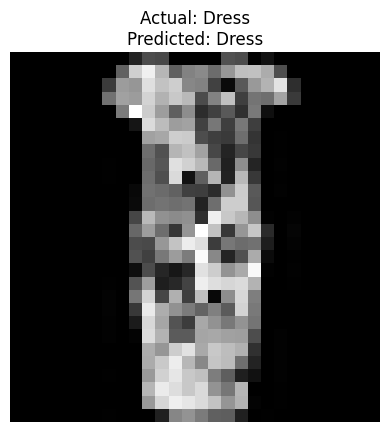

In [19]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis("off")
plt.show()

In [20]:
model.save("fashion_cnn.keras")

In [21]:
import os

print(os.path.getsize("fashion_cnn.keras"), "bytes")

2740031 bytes


In [22]:
style_knowledge = {

    "T-shirt/top": {
        "use": "Casual everyday wear",
        "styling": [
            "Pair with jeans or chinos",
            "Layer with a denim or casual jacket",
            "Sneakers work well for a casual outfit"
        ]
    },

    "Trouser": {
        "use": "Formal, semi-formal, and everyday wear",
        "styling": [
            "Pair with a formal shirt for office wear",
            "Combine with a T-shirt for a casual look",
            "Loafers or sneakers can be selected depending on the occasion"
        ]
    },

    "Pullover": {
        "use": "Casual and cold-weather clothing",
        "styling": [
            "Wear with jeans",
            "Layer over a T-shirt",
            "Pair with sneakers or casual boots"
        ]
    },

    "Dress": {
        "use": "Casual, formal, and occasion-based wear",
        "styling": [
            "Pair with flats for a casual look",
            "Use heels for formal occasions",
            "Add a cardigan or jacket for layering"
        ]
    },

    "Coat": {
        "use": "Cold-weather and formal outerwear",
        "styling": [
            "Wear over shirts, sweaters, or dresses",
            "Pair with trousers for a formal look",
            "Boots complement a coat well"
        ]
    },

    "Sandal": {
        "use": "Casual and warm-weather footwear",
        "styling": [
            "Works well with shorts",
            "Pair with summer dresses",
            "Suitable for casual outdoor outfits"
        ]
    },

    "Shirt": {
        "use": "Casual, business-casual, and formal wear",
        "styling": [
            "Pair with trousers for formal wear",
            "Wear with jeans for casual styling",
            "Layer under a blazer for a polished look"
        ]
    },

    "Sneaker": {
        "use": "Casual footwear, walking, and sports activities",
        "styling": [
            "Pair with jeans",
            "Wear with joggers for a sporty outfit",
            "Neutral sneakers are versatile for everyday outfits"
        ]
    },

    "Bag": {
        "use": "Carrying personal items and accessories",
        "styling": [
            "Choose a bag that complements the outfit",
            "Neutral colors work with many outfits",
            "Use structured bags for formal occasions"
        ]
    },

    "Ankle boot": {
        "use": "Casual, smart-casual, and cold-weather footwear",
        "styling": [
            "Pair with jeans",
            "Works well with dresses and skirts",
            "Can complement coats and jackets"
        ]
    }
}

In [23]:
def style_advisor(item):

    info = style_knowledge[item]

    response = f"""
## Fashion Item: {item}

### Common Use
{info["use"]}

### Styling Suggestions
"""

    for suggestion in info["styling"]:
        response += f"\n- {suggestion}"

    return response

In [24]:
print(style_advisor("Sneaker"))


## Fashion Item: Sneaker

### Common Use
Casual footwear, walking, and sports activities

### Styling Suggestions

- Pair with jeans
- Wear with joggers for a sporty outfit
- Neutral sneakers are versatile for everyday outfits


In [25]:
def fashion_agent(image):

    # Preprocess image
    image = tf.convert_to_tensor(image)

    # Convert RGB to grayscale if necessary
    if len(image.shape) == 3 and image.shape[-1] == 3:
        image = tf.image.rgb_to_grayscale(image)

    # Resize
    image = tf.image.resize(image, (28, 28))

    # Normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # CNN prediction
    predictions = model.predict(image, verbose=0)

    predicted_index = np.argmax(predictions[0])

    item = class_names[predicted_index]

    confidence = predictions[0][predicted_index]

    # Agent
    advice = style_advisor(item)

    result = f"""
# Fashion AI Advisor

**Predicted Item:** {item}

**Confidence:** {confidence * 100:.2f}%

---

{advice}
"""

    return result

In [26]:
import gradio as gr

In [27]:
demo = gr.Interface(
    fn=fashion_agent,
    inputs=gr.Image(type="numpy"),
    outputs=gr.Markdown(),
    title="Fashion Item Classification & Style Advisor",
    description=(
        "Upload a fashion item image. "
        "The CNN identifies the item and the AI agent "
        "provides common uses and styling suggestions."
    )
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b218efa6a39d22b481.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [28]:
import random

def random_fashion_image():
    index = random.randint(0, len(x_test) - 1)

    image = x_test[index]

    return image.squeeze()

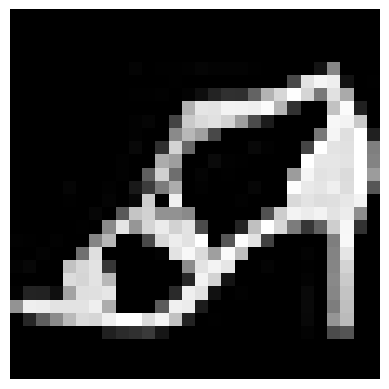

In [29]:
sample = random_fashion_image()

plt.imshow(sample, cmap="gray")
plt.axis("off")
plt.show()